# HW0 — Python and Streamflow Analysis

CEE 306: Hydrology — Water and Climate | Spring 2026

Selected coursework analyzing streamflow and precipitation around Stony Brook, New Jersey. Original code and results are retained.


**Name:** `Sayfullo Saidov`

## Introduction

Python and Jupyter exercises followed by precipitation and streamflow analysis.


In [1]:
# example 1

a = 20

a = a + 10

print(a)

30


In [2]:
# example 2

b = 20

In [3]:
#Run this a few times and see how the result changes!

b = b + 10

print (b)

30


## Importing and accessing data


In [4]:
# within a code cell, any line starting with "#" is ignored
# codes ought to be full of comments to help the writer and any reader understand

import pandas as pd # pandas functions can now be accessed by typing "pd." and then the name of the function
#import requests

In [5]:
# reading the URL, you can see it contains the site number, start date, and end date
# copy and paste the URL into a web server to see what Pandas will be accessing
url = "https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites=01401000&startDT=2021-01-01&endDT=2022-01-15&siteStatus=all"

# we can also make the url an f-string so it takes the variables such as site number, start and end date as inputs
start_date = "2021-01-01"
end_date = "2022-01-15"
site_no = "01401000"

# create url to load data from
url = f'https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites={site_no}&startDT={start_date}&endDT={end_date}&siteStatus=all' 
print(url)

https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites=01401000&startDT=2021-01-01&endDT=2022-01-15&siteStatus=all


In [6]:
StonyBrook_daily = pd.read_csv(url, skiprows=35, sep='\t', header=None)
StonyBrook_daily

,0,1,2,3,4,5,6,7,8,9,10
0,USGS,1401000,2021-01-03,4.5,A,3.9,A,4.2,A,153.0,A
1,USGS,1401000,2021-01-04,5.3,A,4.1,A,4.7,A,145.0,A
2,USGS,1401000,2021-01-05,5.4,A,4.7,A,5.0,A,104.0,A
3,USGS,1401000,2021-01-06,NaN,NaN,NaN,NaN,NaN,NaN,81.4,A
4,USGS,1401000,2021-01-07,4.3,A,2.4,A,3.3,A,66.3,A
...,...,...,...,...,...,...,...,...,...,...,...
373,USGS,1401000,2022-01-11,NaN,NaN,NaN,NaN,NaN,NaN,52.2,A
374,USGS,1401000,2022-01-12,NaN,NaN,NaN,NaN,NaN,NaN,45.9,A
375,USGS,1401000,2022-01-13,NaN,NaN,NaN,NaN,NaN,NaN,42.9,A
376,USGS,1401000,2022-01-14,NaN,NaN,NaN,NaN,NaN,NaN,42.6,A


In [7]:
StonyBrook_daily.columns = ["0","1","datetime","3","4","5","6","7","8","Flow","10"]
## we make a data frame called "StonyBrook_daily" and this data frame has properties and ways we can access the data.
## usually this access is through a command that appears as a ".command(arguments)" type format.  Below we look at a few lines of
## data, using the "head()" command:
StonyBrook_daily.head()

,0,1,datetime,3,4,5,6,7,8,Flow,10
0,USGS,1401000,2021-01-03,4.5,A,3.9,A,4.2,A,153.0,A
1,USGS,1401000,2021-01-04,5.3,A,4.1,A,4.7,A,145.0,A
2,USGS,1401000,2021-01-05,5.4,A,4.7,A,5.0,A,104.0,A
3,USGS,1401000,2021-01-06,NaN,NaN,NaN,NaN,NaN,NaN,81.4,A
4,USGS,1401000,2021-01-07,4.3,A,2.4,A,3.3,A,66.3,A


## Data manipulation


In [8]:
# drop columns by name
StonyBrook_daily = StonyBrook_daily.drop(columns=["0","1","3","4","5","6","7","8","10"])

# rename the remaining column to include units
StonyBrook_daily = StonyBrook_daily.rename(columns={"Flow": "Flow (cfs)"})

StonyBrook_daily.head()

,datetime,Flow (cfs)
0,2021-01-03,153.0
1,2021-01-04,145.0
2,2021-01-05,104.0
3,2021-01-06,81.4
4,2021-01-07,66.3


In [9]:
# apply the conversion
StonyBrook_daily['Flow (cms)'] = StonyBrook_daily['Flow (cfs)']*0.0283168
StonyBrook_daily.head()

,datetime,Flow (cfs),Flow (cms)
0,2021-01-03,153.0,4.332470
1,2021-01-04,145.0,4.105936
2,2021-01-05,104.0,2.944947
3,2021-01-06,81.4,2.304988
4,2021-01-07,66.3,1.877404


## Precipitation data


In [10]:
# Read-in precipitation data and convert to mm
url = "https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=PRCP&stations=US1NJSM0091&startDate=2021-01-01&endDate=2022-01-15"
Franklin_met = pd.read_csv(url, skiprows=0)
Franklin_met['PRCP'] /= 10.
Franklin_met.head()


,STATION,DATE,PRCP
0,US1NJSM0091,2021-01-01,8.9
1,US1NJSM0091,2021-01-02,17.5
2,US1NJSM0091,2021-01-03,0.0
3,US1NJSM0091,2021-01-04,3.8
4,US1NJSM0091,2021-01-05,0.0


## Plotting precipitation and streamflow


In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as dates

<AxesSubplot:>

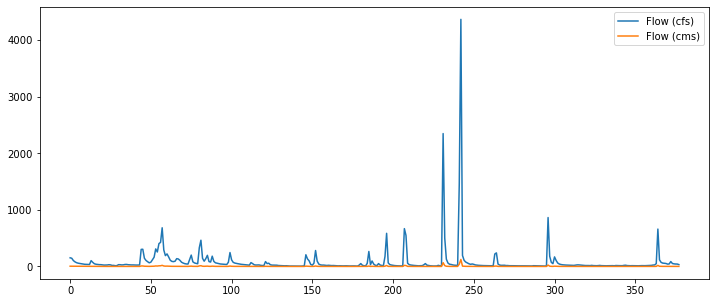

In [12]:
StonyBrook_daily.plot(figsize=(12,5))

Text(0.5, 1.0, '2021 Stony Brook Precipitation and Flow')

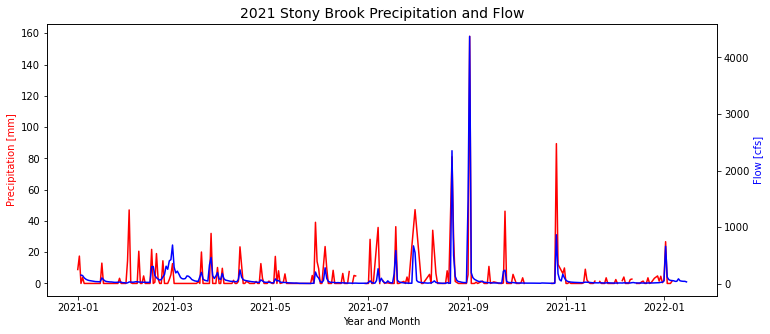

In [13]:
fig, ax1 = plt.subplots(figsize=(12,5)) #creates a figure with each plot 12 wide by 5 high

date = pd.to_datetime(Franklin_met['DATE']) #transform dates from 'string' to a 'datetime' object
ax1.plot(date, Franklin_met['PRCP'],color='red',linestyle='-',markersize=1)
ax1.set_ylabel('Precipitation [mm]',color='red')
ax1.set_xlabel('Year and Month') #if simply using pyplot (plt.plot()) you would call plt.xlabel('text')

#set up a twin axis
ax2 = ax1.twinx()

date = pd.to_datetime(StonyBrook_daily['datetime'])
ax2.plot(date, StonyBrook_daily['Flow (cfs)'],color='blue',linestyle='-',markersize=1) # .plot takes in x, y, then other optional commands
ax2.set_ylabel('Flow [cfs]',color='blue')

ax1.set_title('2021 Stony Brook Precipitation and Flow',fontsize=14)

## Hydrologic analysis


### September 2021 rainfall event


> **Answer:** September 2021 coincides with **Hurricane Ida**, which impacted the Eastern United States.


### Event-scale precipitation and streamflow


(18870.0, 18874.0)

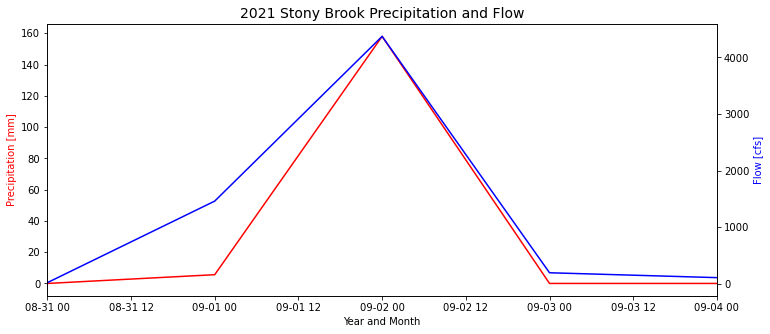

In [67]:
## Q2

#plot graph code from the above:
fig, ax1 = plt.subplots(figsize=(12,5)) 

date = pd.to_datetime(Franklin_met['DATE']) 
ax1.plot(date, Franklin_met['PRCP'],color='red',linestyle='-',markersize=1)
ax1.set_ylabel('Precipitation [mm]',color='red')
ax1.set_xlabel('Year and Month') 


ax2 = ax1.twinx()

date = pd.to_datetime(StonyBrook_daily['datetime'])
ax2.plot(date, StonyBrook_daily['Flow (cfs)'],color='blue',linestyle='-',markersize=1) 
ax2.set_ylabel('Flow [cfs]',color='blue')

ax1.set_title('2021 Stony Brook Precipitation and Flow',fontsize=14)

# Zooms into early September 2021:
ax1.set_xlim(pd.to_datetime('2021-08-31'),
             pd.to_datetime('2021-09-04'))

#because ax2 and ax1 are twins, having ax1.set_xlim is enough


### Water year 2021: cumulative precipitation and streamflow


In [68]:
## Q3.1

start_date = "2020-10-01"
end_date   = "2021-09-30"
site_no = "01401000"

url = f'https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites={site_no}&startDT={start_date}&endDT={end_date}&siteStatus=all'
print(url)

StonyBrook_daily = pd.read_csv(url, skiprows=33, sep='\t', header=None)

StonyBrook_daily.columns = ["0","1","datetime","3","4","5","6","7","8","Flow","10"]
StonyBrook_daily = StonyBrook_daily.drop(columns=["0","1","3","4","5","6","7","8","10"])
StonyBrook_daily = StonyBrook_daily.rename(columns={"Flow": "Flow (cfs)"})
StonyBrook_daily.head()


https://waterservices.usgs.gov/nwis/dv/?format=rdb&sites=01401000&startDT=2020-10-01&endDT=2021-09-30&siteStatus=all


,datetime,Flow (cfs)
0,2020-10-01,62.4
1,2020-10-02,30.8
2,2020-10-03,21.1
3,2020-10-04,15.1
4,2020-10-05,12.6


In [69]:
## Q3.1 continuation 
url = "https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=PRCP&stations=US1NJSM0091&startDate=2020-10-01&endDate=2021-09-30"
print(url)
Franklin_met = pd.read_csv(url, skiprows=0)
Franklin_met['PRCP'] /= 10.
Franklin_met.head()

https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&dataTypes=PRCP&stations=US1NJSM0091&startDate=2020-10-01&endDate=2021-09-30


,STATION,DATE,PRCP
0,US1NJSM0091,2020-11-22,0.0
1,US1NJSM0091,2020-11-23,5.1
2,US1NJSM0091,2020-11-24,0.0
3,US1NJSM0091,2020-11-25,0.0
4,US1NJSM0091,2020-11-26,15.0


Text(0.5, 1.0, 'Stony Brook Precipitation and Flow — Water Year 2021\n(October 1, 2020 to September 30, 2021)')

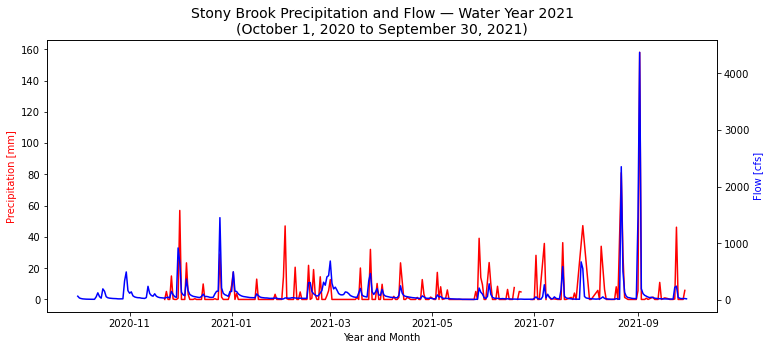

In [70]:
##Q3.1 - reused the plot code from the previous examples 

fig, ax1 = plt.subplots(figsize=(12,5)) 

date = pd.to_datetime(Franklin_met['DATE']) 
ax1.plot(date, Franklin_met['PRCP'],color='red',linestyle='-',markersize=1)
ax1.set_ylabel('Precipitation [mm]',color='red')
ax1.set_xlabel('Year and Month') 


ax2 = ax1.twinx()

date = pd.to_datetime(StonyBrook_daily['datetime'])
ax2.plot(date, StonyBrook_daily['Flow (cfs)'],color='blue',linestyle='-',markersize=1) 
ax2.set_ylabel('Flow [cfs]',color='blue')

ax1.set_title(
    'Stony Brook Precipitation and Flow — Water Year 2021\n'
    '(October 1, 2020 to September 30, 2021)',
    fontsize=14)

In [71]:
## Q3.2 Compute a cumulative sum of the precipitation and streamflow in a new column in the Pandas data frame

#Firstly, for precipitation:

Franklin_met['PRCP_cum_mm'] = Franklin_met['PRCP'].cumsum()
Franklin_met[['DATE', 'PRCP', 'PRCP_cum_mm']].head()

,DATE,PRCP,PRCP_cum_mm
0,2020-11-22,0.0,0.0
1,2020-11-23,5.1,5.1
2,2020-11-24,0.0,5.1
3,2020-11-25,0.0,5.1
4,2020-11-26,15.0,20.1


In [72]:
#Secondly, cumulative sum for Flow:

#the flow rate we have is in cubic feet per seconds. We need to convert that into per day, that's the first step. 

seconds_per_day = 86400  #86400 seconds in one day
StonyBrook_daily['Flow_cf_day'] = StonyBrook_daily['Flow (cfs)'] * seconds_per_day

StonyBrook_daily['Flow_cum_cf'] = StonyBrook_daily['Flow_cf_day'].cumsum()
StonyBrook_daily[['datetime', 'Flow (cfs)', 'Flow_cum_cf']].head()

,datetime,Flow (cfs),Flow_cum_cf
0,2020-10-01,62.4,5391360.0
1,2020-10-02,30.8,8052480.0
2,2020-10-03,21.1,9875520.0
3,2020-10-04,15.1,11180160.0
4,2020-10-05,12.6,12268800.0


In [73]:
## Q3.3 Print these values in metric and imperial / US units.

Franklin_met['PRCP_cum_in'] = Franklin_met['PRCP_cum_mm'] / 25.4 #conversion from mm to inches

#As I want to print only the cumulative sum, it should be the last cell in the column that has the total cumulative sum.
#So, I print the last cell - location is [-1]

total_PRCP_mm = Franklin_met['PRCP_cum_mm'].iloc[-1]
total_PRCP_in = Franklin_met['PRCP_cum_in'].iloc[-1]

print(f"Total precipitation for Water Year 2021:")
print(f"  Metric: {total_PRCP_mm:.1f} mm")
print(f"  US/Imperial: {total_PRCP_in:.2f} in")



Total precipitation for Water Year 2021:
  Metric: 1214.9 mm
  US/Imperial: 47.83 in


In [74]:
#similar code to what I did for precipitation:

StonyBrook_daily['Flow_cum_m3'] = StonyBrook_daily['Flow_cum_cf'] * 0.0283168 #formula from above to convert cf -> m^3 (cubic meter)


total_flow_cf = StonyBrook_daily['Flow_cum_cf'].iloc[-1]
total_flow_m3 = StonyBrook_daily['Flow_cum_m3'].iloc[-1]

print(f"Cumulative streamflow for Water Year 2021:")
print(f"  US units: {total_flow_cf:,.0f} ft^3")
print(f"  Metric: {total_flow_m3:,.0f} m^3")

Cumulative streamflow for Water Year 2021:
  US units: 3,204,686,592 ft^3
  Metric: 90,746,469 m^3


### Precipitation and streamflow volumes


Watershed area of Stony Brook is: 115,255,000 m^2


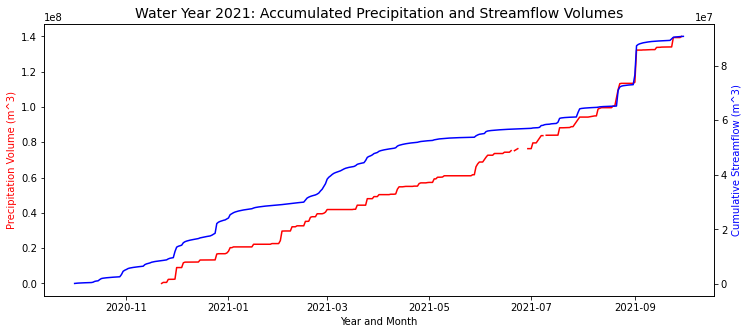

In [76]:
## Q4

# watershed area in m² (converted) - according to the website of USGS for station: USGS-01401000
watershed_area_miles2 = 44.5 
watershed_area_m2 = watershed_area_miles2 * 2.59e6
print(f"Watershed area of Stony Brook is: {watershed_area_m2:,.0f} m^2")

# converting PRCP from mm to m
Franklin_met['PRCP_cum_m'] = Franklin_met['PRCP_cum_mm'] * 0.001

# cumulative precipitation volume in m³ -> height x area
Franklin_met['PRCP_cum_m3'] = Franklin_met['PRCP_cum_m'] * watershed_area_m2

fig, ax1 = plt.subplots(figsize=(12,5))
dates = pd.to_datetime(Franklin_met['DATE'])

ax1.plot(dates, Franklin_met['PRCP_cum_m3'], color='red', linestyle='-',markersize=1)
ax1.set_ylabel('Precipitation Volume (m^3)', color='red')
ax1.set_xlabel('Year and Month')

ax2 = ax1.twinx()
dates = pd.to_datetime(StonyBrook_daily['datetime'])
ax2.plot(dates, StonyBrook_daily['Flow_cum_m3'], color='blue', linestyle='-',markersize=1)
ax2.set_ylabel('Cumulative Streamflow (m^3)', color='blue')


ax1.set_title('Water Year 2021: Accumulated Precipitation and Streamflow Volumes', fontsize=14)

plt.show()

### Runoff ratio


In [50]:
print(Franklin_met[['DATE', 'PRCP_cum_m3']].tail())  #i used tail (opposite of head) to double-check the final values
print("\n")
print(StonyBrook_daily[['datetime', 'Flow_cum_m3']].tail())

           DATE  PRCP_cum_m3
270  2021-09-24  139354820.5
271  2021-09-25  139354820.5
272  2021-09-27  139354820.5
273  2021-09-28  139354820.5
274  2021-09-29  140023299.5


       datetime   Flow_cum_m3
360  2021-09-26  9.055808e+07
361  2021-09-27  9.060653e+07
362  2021-09-28  9.065521e+07
363  2021-09-29  9.070708e+07
364  2021-09-30  9.074647e+07


In [54]:
## Q5.1

total_PRCP_m3 = Franklin_met['PRCP_cum_m3'].iloc[-1]
total_flow_m3 = StonyBrook_daily['Flow_cum_m3'].iloc[-1] #redoing but already created this variable in above cells

print(f"Accumulated PRCP is: {total_PRCP_m3:,.1f} m^3")
print(f"Accumulated Flow is: {total_flow_m3:,.1f} m^3")

ratio = total_flow_m3 / total_PRCP_m3
print(f"\nRatio is: {ratio:.2f}")


Accumulated PRCP is: 140,023,299.5 m^3
Accumulated Flow is: 90,746,469.3 m^3

Ratio is: 0.65


*Q5.2 answer*

> ratio = flow/precipitation is generally called the runoff coefficient. Specifically, it is a fraction of precipitation (rain) that is converted into runoff and observed as streamflow.

> The values are not the same because not all precipitation becomes runoff. When the precipitation (rain, snow) occurs, some water evaporates, some soaks into the ground to become a groundwater, and some becomes part of the river, runoff. 

> Based on my value of 0.65, I can deduce that around 65% of precipitated water is turning into streamflow over this watershed area in WY 2021. The rest of 35% is lost to evaporation, infiltration, or other ways within this watershed.

### Tributary flow and missing-data handling


In [66]:
## Q6.1 (Modify code below)

# Flow data for the main river and it tributary
# DO NOT CHANGE THE NEXT 3 LINES
days = ['2025-01-05', '2025-01-06', '2025-01-07', '2025-01-08','2025-01-09', '2025-01-10','2025-01-11']
flow_main = [24, 19, 30, 26, 20, 18, 17]
flow_tributary = ['7', '3', '-9999', '10', '8', '3', '3']

import numpy as np

# Get flow for main river into a pandas DataFrame
main_river = pd.DataFrame({'day':days, 'flow':flow_main})

# Get flow for tributary into a pandas DataFrame
downstream_tributary =  pd.DataFrame({'day':days, 'flow': flow_tributary}) 
downstream_tributary['flow'] = pd.to_numeric(downstream_tributary['flow'].replace('-9999', np.nan))

#the issue is happening because we are trying to combine integer with a string. Moreover, negative value -9999 for flow is wrong. 


# Find the combined flow
combined_flow = main_river['flow'] + downstream_tributary['flow']

# Make a dataframe with dates + combined flow values
combined_flow_df = pd.DataFrame({'day':days, 'flow':combined_flow})

# Print your result 
print('Combined flow')
print(combined_flow_df)

Combined flow
          day  flow
0  2025-01-05  31.0
1  2025-01-06  22.0
2  2025-01-07   NaN
3  2025-01-08  36.0
4  2025-01-09  28.0
5  2025-01-10  21.0
6  2025-01-11  20.0


*Q6.2 answer here*

> The wrong one seems to be the January 7th's tributary flow value. It could be due to sensor error or missing measurement. So, I handled it by replacing -9999 with NaN to clearly indicate the error happened that day. 

### Tools and assistance disclosure


> I used ChatGPT to search for pandas & matplotlib methods such as set_xlim, cumsum, replace. They were used and implemented to the code by myself